In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

In [2]:
hom_df = pd.read_csv("plotting_data/df_gmm_homozygous.tsv", sep="\t").set_index("Unnamed: 0")
cohort_df = pd.read_csv("plotting_data/df_gmm_cohort.tsv", sep="\t").set_index("Unnamed: 0")

In [3]:
hom_df["STRONG_TRUNC"] = hom_df[["0.6", "0.8", "1.0", "1.2", "1.4"]].sum(axis=1)
hom_df["WEAK_TRUNC"] = hom_df[["1.6", "1.8"]].sum(axis=1)
hom_df["NORMAL"] = hom_df[["2.0", "2.2"]].sum(axis=1)
hom_df["LONGER"] = hom_df[["2.4", "2.6"]].sum(axis=1)

In [4]:
cohort_df["STRONG_TRUNC"] = cohort_df[["0.6", "0.8", "1.0", "1.2", "1.4"]].sum(axis=1)
cohort_df["WEAK_TRUNC"] = cohort_df[["1.6", "1.8"]].sum(axis=1)
cohort_df["NORMAL"] = cohort_df[["2.0", "2.2"]].sum(axis=1)
cohort_df["LONGER"] = cohort_df[["2.4", "2.6"]].sum(axis=1)

In [5]:
common_index = hom_df.index.intersection(cohort_df[cohort_df["N"] > 10].index)

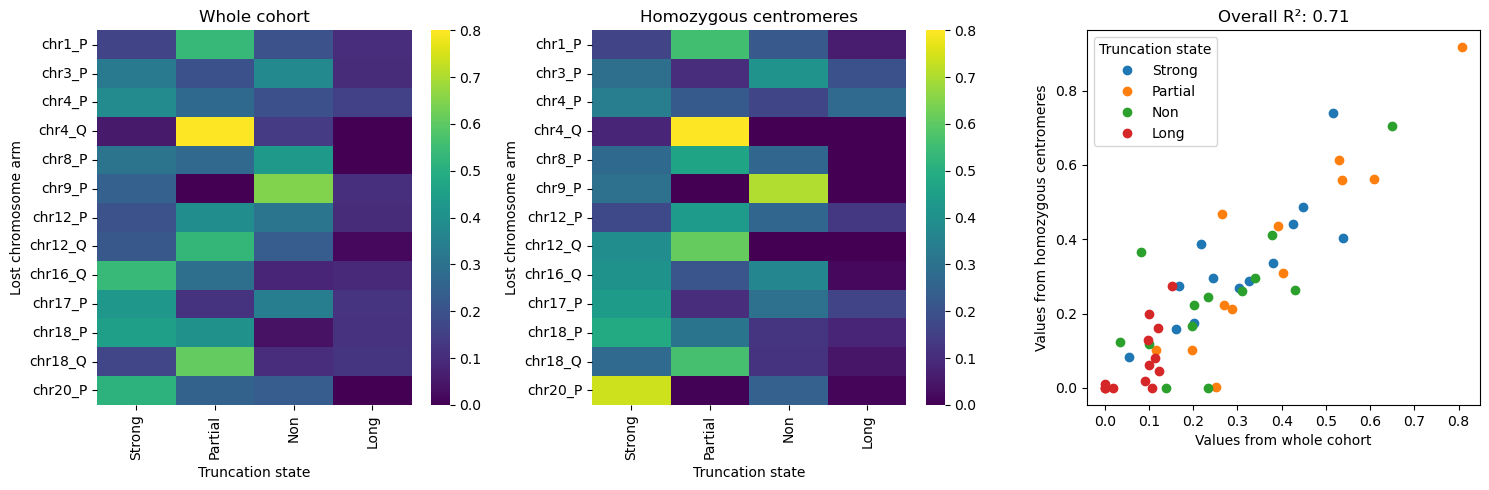

In [ ]:
ax1 = plt.subplot(1, 3, 1)
sns.heatmap(cohort_df.loc[common_index][["STRONG_TRUNC", "WEAK_TRUNC", "NORMAL", "LONGER"]], ax=ax1, vmin=0, vmax=0.8, cmap="viridis")
ax1.set_title("Whole cohort")

ax2 = plt.subplot(1, 3, 2)
sns.heatmap(hom_df.loc[common_index][["STRONG_TRUNC", "WEAK_TRUNC", "NORMAL", "LONGER"]], ax=ax2, vmin=0, vmax=0.8, cmap="viridis")
ax2.set_title("Homozygous centromeres")

for ax in [ax1, ax2]:
    ax.set_ylabel("Lost chromosome arm")
    ax.set_xticks([0.5, 1.5, 2.5, 3.5])
    ax.set_xticklabels(["Strong", "Partial", "Non", "Long"])
    ax.set_xlabel("Truncation state")
    
ax3 = plt.subplot(1, 3, 3)

cohort_values = cohort_df.loc[common_index, ["STRONG_TRUNC", "WEAK_TRUNC", "NORMAL", "LONGER"]]
hom_values = hom_df.loc[common_index, ["STRONG_TRUNC", "WEAK_TRUNC", "NORMAL", "LONGER"]]

x = []
y = []

for group, label in [("STRONG_TRUNC", "Strong"), ("WEAK_TRUNC", "Partial"), ("NORMAL", "Non"), ("LONGER", "Long")]:
    ax3.plot(cohort_values[group], hom_values[group], "o", label=label)
    x.extend(cohort_values[group])
    y.extend(hom_values[group])

ax3.set_title(f"Overall R²: {r2_score(x, y):.2f}")

ax3.legend(title="Truncation state")
ax3.set_xlabel("Values from whole cohort")
ax3.set_ylabel("Values from homozygous centromeres")

plt.gcf().set_size_inches(15, 5)
plt.tight_layout()
plt.savefig("plots/revision_figure4c_comparison.png")
plt.show()